# Ablation Study on Variant Annotation Dimensions

To dissect the contribution of different sources of variant annotation, we perform a **dimension-wise ablation analysis** on the IEI cohort. Rather than removing one component from a full model (classical ablation), we construct **minimalist models**, each augmenting a shared *basic* prompt with **only one additional annotation dimension**:

| Model | Annotation Content                                                                    |
|------|---------------------------------------------------------------------------------------|
| `basic` | Chromosome, position, reference/alternate alleles, zygosity |
| `af`    | `basic` + allele frequency (gnomAD, etc.)                                             |
| `ACMG`  | `basic` + ACMG pathogenicity criteria (e.g., PVS1, PM2)                               |
| `dbsig` | `basic` + curated database significance (ClinVar, HGMD)                               |
| `pred`  | `basic` + in silico deleteriousness (SIFT, PolyPhen, CADD, etc.)                      |
| `dis`   | `basic` + gene–disease association strength (from OMIM)                               |
| `IUIS`  | `basic` + IEI-specific gene membership (from IUIS 2024 classification)                |
| `all`   | Full prompt: `basic` + all six dimensions above                                       |

> **Note**: This is **not a leave-one-out ablation**, but a *building-up* design—each ablated model sees only its designated annotation type beyond basic genomic context. This isolates the predictive utility of each knowledge source.

## Training & Inference Protocol

All ablated models were:
- Initialized from the same base LLM checkpoint as the main VIPER model
- Trained for **1.5 epochs** (empirically optimal for small ablation sets)
- Optimized **without loss scaling**
- Inferred using **PyTorch `pt` backend with eager attention** (for reproducibility)
- Evaluated using the **exact same metrics and pipeline** as in the main evaluation (`evaluation.ipynb`)

Full prompt construction followed the `VarAnno2LLM` toolkit ([GitHub](https://github.com/VincentLHH/VarAnno2LLM)), using command-line flags to toggle annotation modules.

Results are summarized in **Supplementary Table S6** (`example_results_ablation.xlsx`), which reports:
- Overall recall of causative variants / samples
- Average Candidate variant count per sample
- Top-k recall

Below, we visualize **pairwise performance differences** across models via heatmap.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_metric_diff_heatmaps(df, save=True):
    """
    Plot pairwise difference heatmaps for ablation study results.

    Input format:
      - Rows: metrics (e.g., 'Mean Rank', 'Top1 Recall', 'Top10 Recall')
      - Columns: model names (e.g., 'basic', 'af', 'ACMG', ..., 'all')
      - Values: metric scores (higher = better, except for 'Mean Rank')

    Output: One heatmap per metric, showing (Model_j - Model_i) at cell (i,j).
    """

    # Validate
    if df.shape[1] < 2:
        raise ValueError("At least two models (columns) are required.")

    metrics = df.index.tolist()
    n_metrics = len(metrics)

    # Determine subplot grid
    n_cols = 2
    n_rows = (n_metrics + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    if n_metrics == 1:
        axes = [axes]
    elif n_rows == 1:
        axes = axes if n_cols > 1 else [axes]
    else:
        axes = axes.flatten()

    # Plot each metric
    for idx, metric in enumerate(metrics):
        ax = axes[idx]
        row_vals = df.loc[metric].values
        model_names = df.columns.tolist()

        # Compute difference matrix
        diff_matrix = row_vals[:, None] - row_vals[None, :]  # shape: (n, n)
        diff_df = pd.DataFrame(diff_matrix, index=model_names, columns=model_names)

        # Plot heatmap
        sns.heatmap(
            diff_df,
            annot=True,
            fmt=".3f",
            cmap="coolwarm",
            center=0.0,
            cbar_kws={"label": f"Δ {metric} (Col - Row)"},
            square=True,
            ax=ax
        )
        ax.set_title(f"{metric}", fontsize=14, pad=12)
        ax.tick_params(axis='x', rotation=45, labelsize=10)
        ax.tick_params(axis='y', rotation=0, labelsize=10)

    # Hide unused subplots
    for idx in range(len(metrics), len(axes)):
        fig.delaxes(axes[idx])

    plt.tight_layout()
    if save:
        output_base = "ablation_pairwise_diff"
        for ext in ['pdf', 'png', 'svg']:
            plt.savefig(f"{output_base}.{ext}", bbox_inches='tight', dpi=300)
        print(f"→ Heatmaps saved as '{output_base}.{{pdf,png,svg}}'")
    plt.show()

In [14]:
df = pd.read_excel("example_results_ablation.xlsx",index_col=0)
df

,basic,ACMG,af,pred,dbsig,dis,IUIS,all
Overall Variant Recall,0.643411,0.751938,0.724806,0.740310,0.717054,0.755814,0.794574,0.767442
Average Candidate Variant Count per sample,6.771689,12.817352,8.493151,8.018265,6.817352,6.383562,20.164384,5.086758
Overall Sample Recall,0.726829,0.804878,0.780488,0.804878,0.790244,0.814634,0.878049,0.829268
Top-1 Recall,0.476744,0.581395,0.515504,0.558140,0.608527,0.581395,0.395349,0.674419
Top-5 Recall,0.724806,0.744186,0.782946,0.779070,0.748062,0.810078,0.666667,0.844961
Top-20 Recall,0.848837,0.895349,0.930233,0.899225,0.895349,0.941860,0.899225,0.972868
Top-35 Recall,0.872093,0.910853,0.965116,0.918605,0.941860,0.976744,0.937984,1.000000
Top-50 Recall,0.906977,0.957364,0.968992,0.937984,0.953488,0.984496,0.965116,1.000000
Top-80 Recall,0.957364,0.980620,0.984496,0.953488,0.976744,0.988372,0.984496,1.000000
Top-100 Recall,0.965116,0.980620,0.988372,0.968992,0.976744,0.988372,0.992248,1.000000


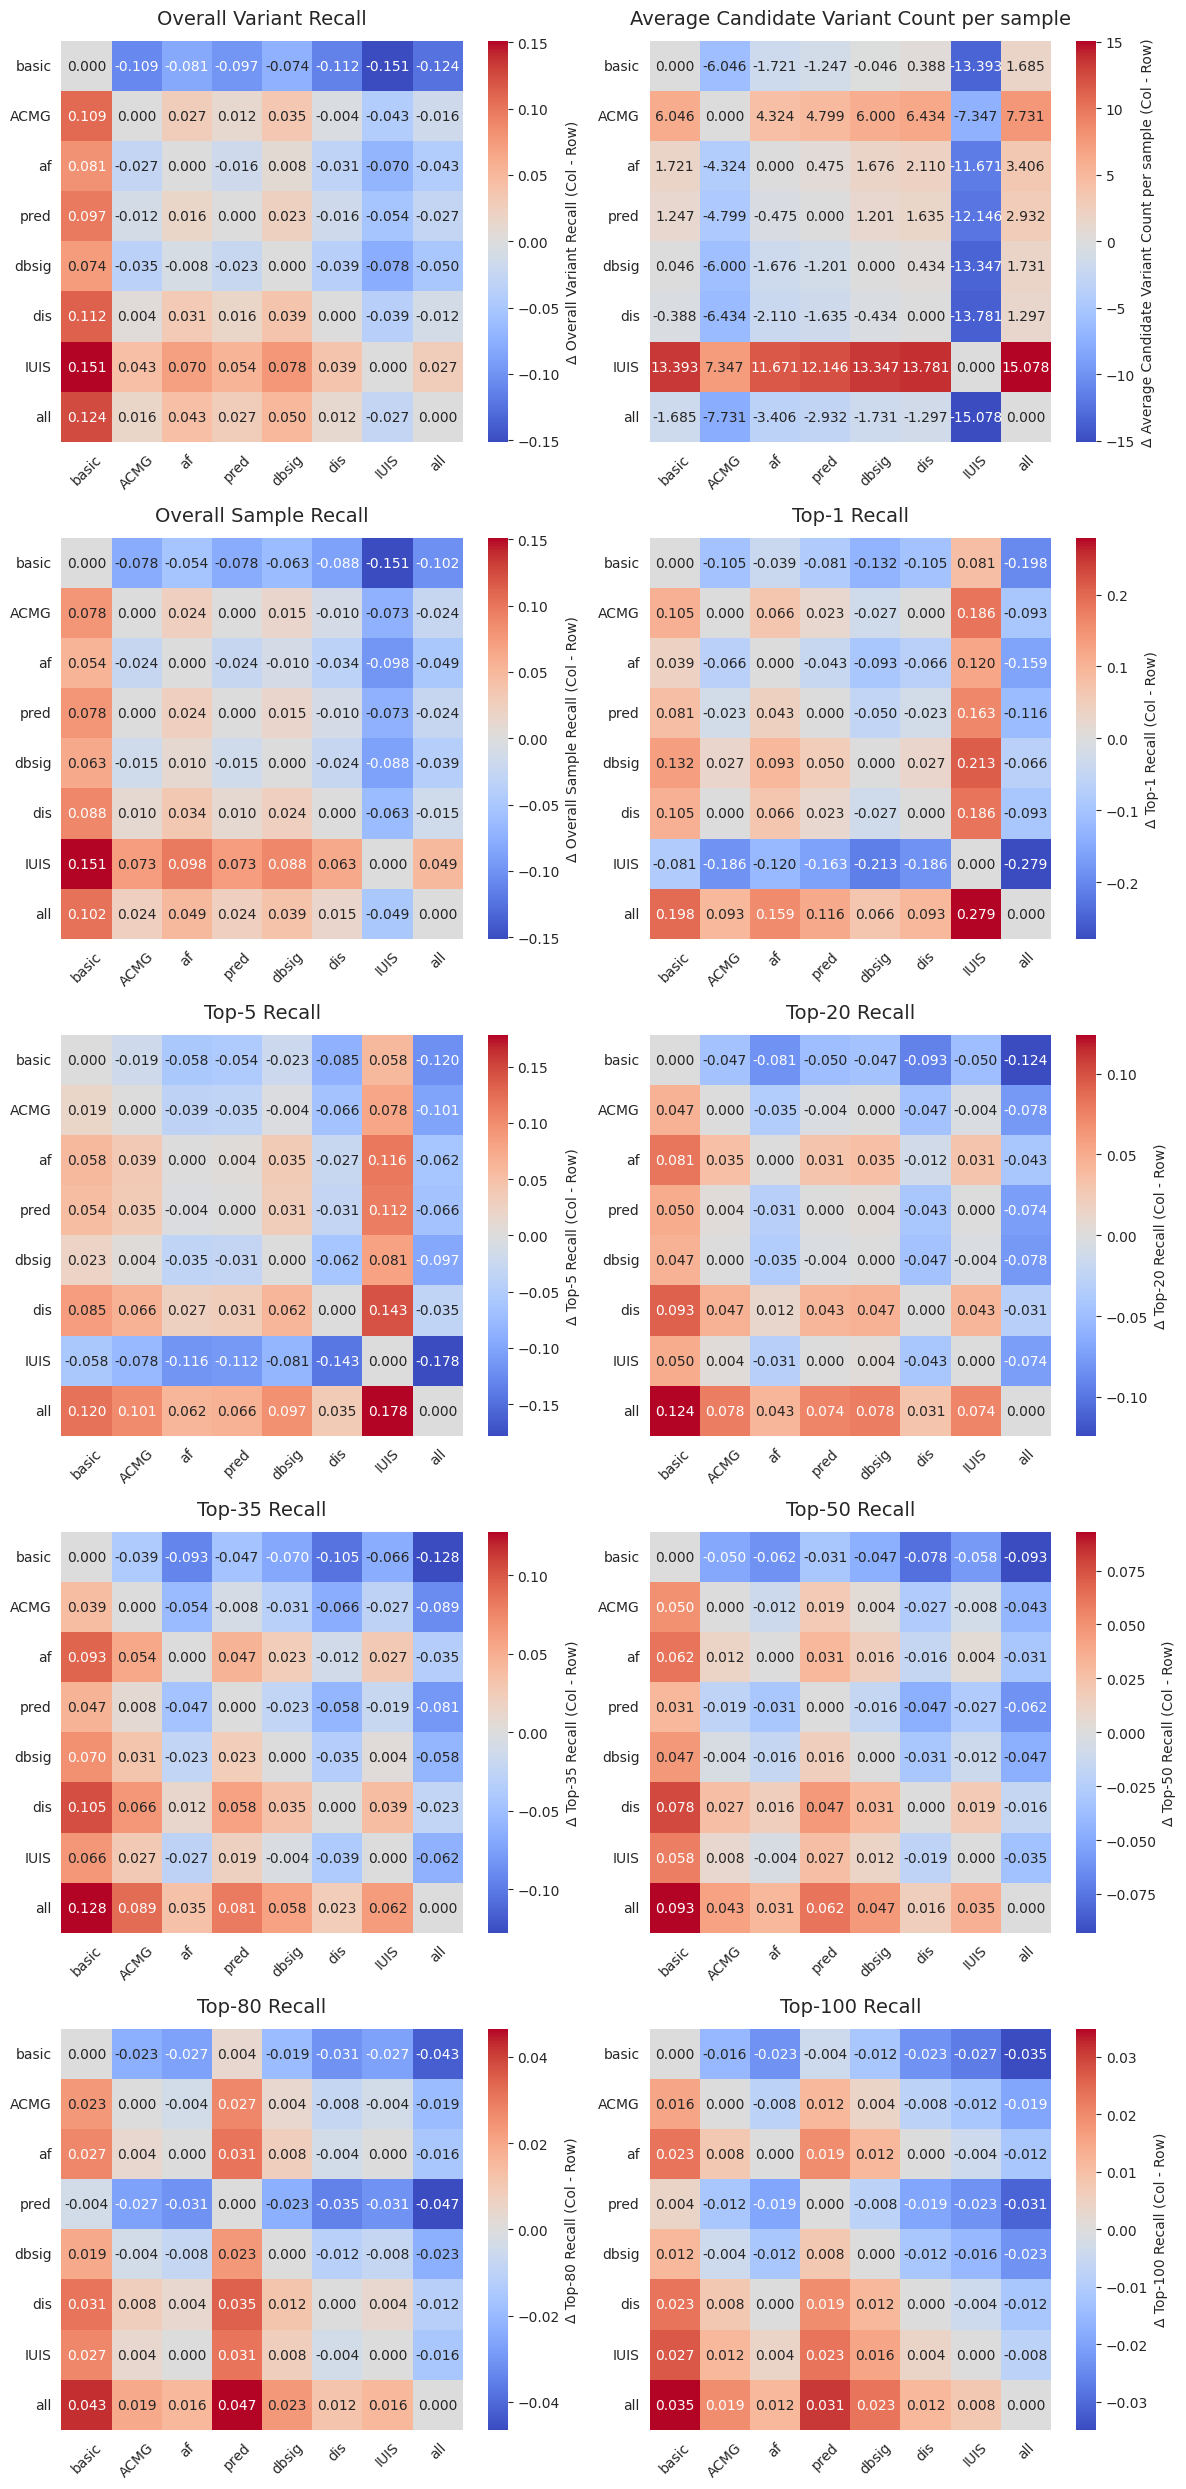

In [15]:
plot_metric_diff_heatmaps(df, save=False)